# 02 · Feature engineering

All features are computed by `src.features.compute_features` from adjusted OHLCV. Each feature at day *t* uses
rows ≤ *t* only. They are scale-invariant (returns, ratios, oscillators) because Yahoo's adjusted *price levels* are
back-adjusted with future corporate actions.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.utils import load_config
cfg = load_config(ROOT / "config.yaml")
RESULTS = ROOT / cfg["experiment"]["results_dir"]

In [2]:
from src.data_loader import load_ticker
from src.features import compute_features, feature_table, feature_groups
ticker = cfg["data"]["tickers"][0]
prices, meta = load_ticker(ticker, cfg["data"]["start"], cfg["data"]["end"], ROOT / cfg["data"]["raw_dir"])
F = compute_features(prices, cfg["features"])
print(ticker, F.shape)
feature_table()

07:46:04 | INFO | SPY: 4024 rows 2010-01-04 -> 2025-12-31 (source=cache)


SPY (4024, 42)


,feature,group,definition,rationale
0,ret_1,returns,Close-to-close return of day t,Most recent price change (short-term reversal/...
1,log_ret_1,returns,Log return ln(C_t/C_{t-1}),"Additive, more symmetric version of the daily ..."
2,ret_lag_1,returns,Return of day t-1,Lagged returns let models detect short-horizon...
3,ret_lag_2,returns,Return of day t-2,Lagged returns let models detect short-horizon...
4,ret_lag_3,returns,Return of day t-3,Lagged returns let models detect short-horizon...
5,ret_lag_5,returns,Return of day t-5,Lagged returns let models detect short-horizon...
6,cum_ret_5,returns,Cumulative return over the last 5 days,Price momentum / rate of change
7,cum_ret_10,returns,Cumulative return over the last 10 days,Price momentum / rate of change
8,cum_ret_20,returns,Cumulative return over the last 20 days,Price momentum / rate of change
9,cum_ret_60,returns,Cumulative return over the last 60 days,Price momentum / rate of change


## Warm-up periods
Indicators need a history window; warm-up rows are NaN and are dropped (never imputed).

In [3]:
F.isna().sum().sort_values(ascending=False).head(10).to_frame("NaN rows (warm-up)")

,NaN rows (warm-up)
vol_regime,271
drawdown_252,251
trend_up,199
trend_regime,199
cum_ret_60,60
vol_ratio_5_60,60
vol_60,60
sma_10_50_ratio,49
close_sma_50,49
close_ema_50,49


## Point-in-time check (truncation invariance)
If features used future data, recomputing them on a truncated history would change past values.

In [4]:
cuts = [600, 1500, 2500, 3500]
ok = all(np.allclose(compute_features(prices.iloc[:c], cfg["features"]).iloc[-1].values, F.iloc[c - 1].values, equal_nan=True) for c in cuts)
print("Features at t identical when all data after t is removed:", ok)

Features at t identical when all data after t is removed: True


## Feature correlation (training period)
Strongly correlated groups (e.g. SMA/EMA ratios) are expected. Tree models cope with this, and Logistic Regression is regularised.

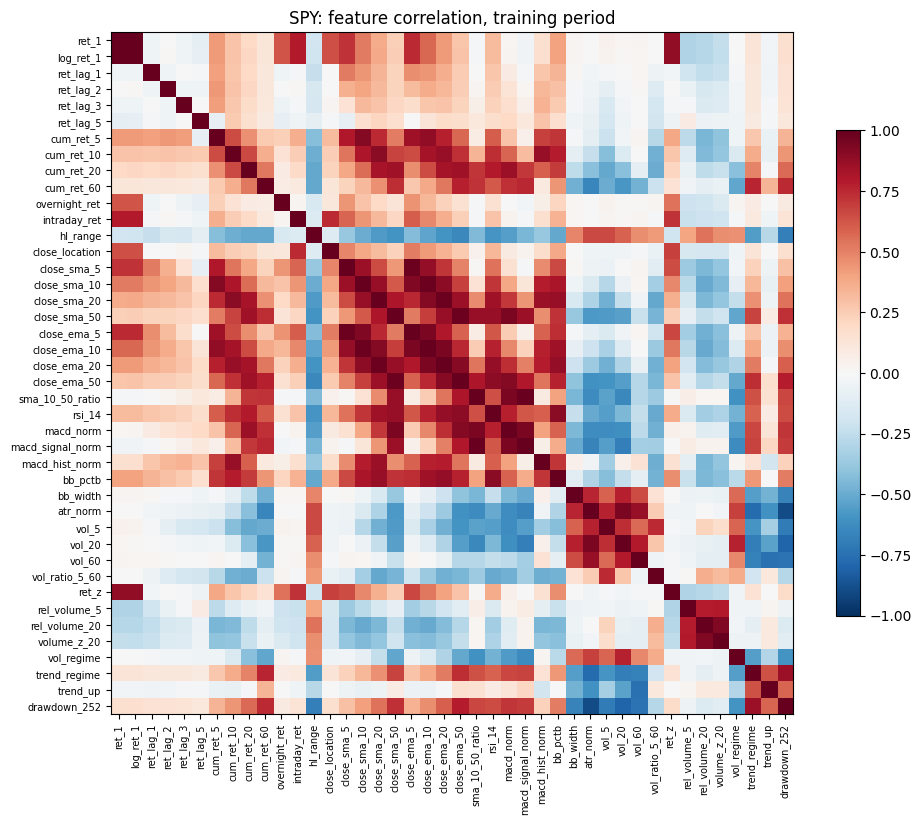

In [5]:
train = F.loc[: cfg["split"]["train_end"]].dropna()
corr = train.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
fig.colorbar(im, shrink=0.7); ax.set_title(f"{ticker}: feature correlation, training period"); plt.show()

## Feature relevance
Mutual information is measured on the training data and permutation importance on the validation data. Importance shows what a model relies on. It does **not** establish causality.

In [6]:
imp_dir = RESULTS / "metrics" / "feature_importance"
mi = pd.read_csv(imp_dir / f"{ticker}_mutual_information.csv")
perm = pd.read_csv(imp_dir / f"{ticker}_xgboost_permutation.csv")
mi.head(15).merge(perm, on="feature", how="left").round(5)

,feature,mutual_information,importance_mean,importance_std
0,macd_norm,0.02775,0.00443,0.00104
1,trend_up,0.02512,0.00000,0.00000
2,trend_regime,0.02460,-0.00006,0.00025
3,cum_ret_5,0.02179,-0.00012,0.00024
4,vol_regime,0.02144,-0.00020,0.00199
5,hl_range,0.02122,0.00064,0.00122
6,ret_z,0.01998,0.00000,0.00007
7,close_location,0.01988,0.00046,0.00045
8,close_ema_20,0.01959,-0.00031,0.00059
9,volume_z_20,0.01895,0.00086,0.00055


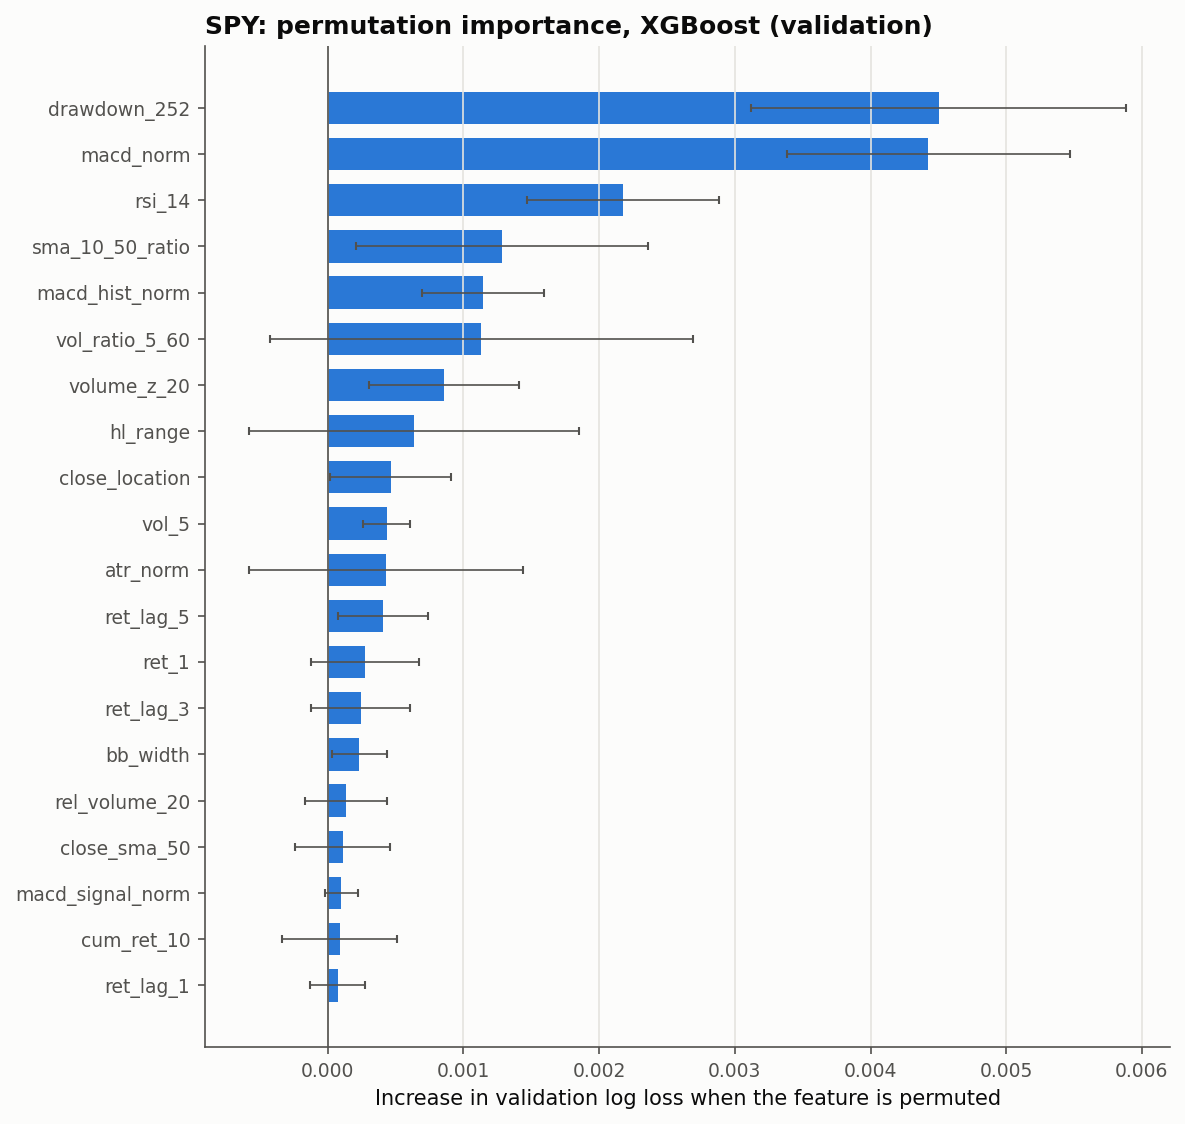

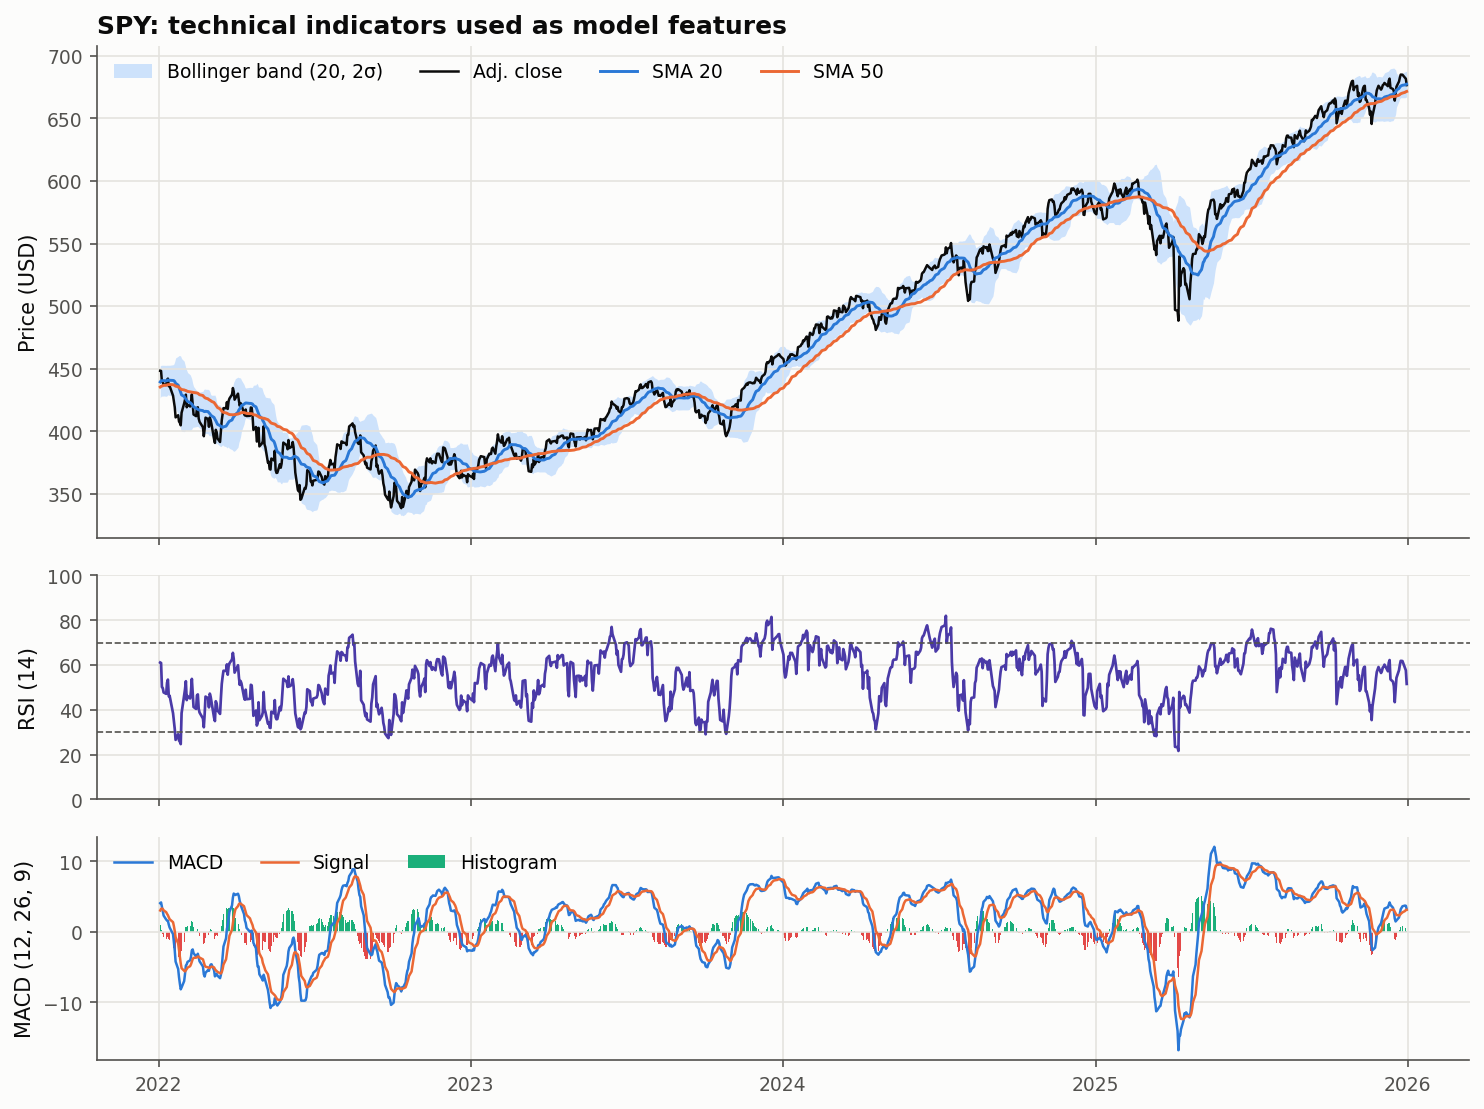

In [7]:
for name in [f"{ticker}_xgboost_permutation_importance.png", f"{ticker}_technical_indicators.png"]:
    p = RESULTS / "figures" / name
    if p.exists(): display(Image(filename=str(p)))

## Feature-group ablation (XGBoost, test period)

In [8]:
pd.read_csv(RESULTS / "metrics" / "feature_ablation.csv").round(4)

,ticker,feature_set,n_features,test_log_loss,test_accuracy,test_f1_macro,threshold,test_sharpe,test_cumulative_return
0,SPY,returns only,14,0.9337,0.4825,0.2437,0.300,0.6613,0.5136
1,SPY,returns + technical,29,0.9349,0.4835,0.2571,0.375,0.6591,0.5088
2,SPY,all except regime,38,0.9386,0.4795,0.2524,0.350,0.6400,0.4898
3,SPY,all except volume,39,0.9370,0.4805,0.2559,0.375,0.5787,0.4241
4,SPY,top-15 by mutual information,15,0.9350,0.4955,0.2633,0.300,0.6465,0.4973
5,SPY,all features,42,0.9375,0.4715,0.2503,0.375,0.6042,0.4516
6,AAPL,returns only,14,0.8927,0.4895,0.2771,0.300,0.5283,0.5627
7,AAPL,returns + technical,29,0.8911,0.4865,0.2741,0.475,0.2488,0.1309
8,AAPL,all except regime,38,0.8917,0.4875,0.2722,0.325,0.5331,0.5695
9,AAPL,all except volume,39,0.8915,0.4845,0.2733,0.325,0.5536,0.6070
